# Chapter 11. Compiling, Exporting, and Serving PyTorch Models

In [ ]:
!pip install "fastapi[standard]" python-multipart requests

In [ ]:
!wget https://github.com/lftraining/LFD273-code/releases/download/model/fomo_model_2026.pth

## 11.2 Learning Objectives

By the end of this chapter, you should be able to:
- benchmark eager-mode inference;
- use `torch.compile()` for inference;
- explain graph capture, graph breaks, guards, and recompilation;
- distinguish `torch.compile()` from `torch.export()`;
- deploy the model using FastAPI.

## 11.3 Loading a Pretrained Model

In [2]:
import torch
checkpoint = torch.load("fomo_model_2026.pth", map_location="cpu", weights_only=True)
repo_id = checkpoint["repo_id"]
labels = checkpoint["labels"]

repo_id, labels

('microsoft/resnet-18', ['Fig', 'Mandarine', 'Onion White', 'Orange'])

In [3]:
from transformers import AutoConfig, AutoImageProcessor, AutoModelForImageClassification

id2label = {idx: label for idx, label in enumerate(labels)}
label2id = {label: idx for idx, label in id2label.items()}

config = AutoConfig.from_pretrained(
    repo_id,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
)

config.json:   0%|          | 0.00/69.5k [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


In [4]:
model = AutoModelForImageClassification.from_config(config)
model.classifier

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=512, out_features=4, bias=True)
)

In [5]:
model.load_state_dict(checkpoint["model_state_dict"])

<All keys matched successfully>

In [6]:
processor = AutoImageProcessor.from_pretrained(repo_id)

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

## 11.4 Running Inference

In [7]:
import torch.nn as nn

class LogitsModel(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, pixel_values):
        return self.model(pixel_values=pixel_values).logits

In [8]:
device = torch.accelerator.current_accelerator(check_available=True) or torch.device("cpu")

eager_model = LogitsModel(model)
eager_model.to(device)
eager_model.eval()

LogitsModel(
  (model): ResNetForImageClassification(
    (resnet): ResNetModel(
      (embedder): ResNetEmbeddings(
        (embedder): ResNetConvLayer(
          (convolution): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
          (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (activation): ReLU()
        )
        (pooler): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      )
      (encoder): ResNetEncoder(
        (stages): ModuleList(
          (0): ResNetStage(
            (layers): Sequential(
              (0): ResNetBasicLayer(
                (shortcut): Identity()
                (layer): Sequential(
                  (0): ResNetConvLayer(
                    (convolution): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
                    (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bia

In [9]:
!wget https://raw.githubusercontent.com/lftraining/LFD273-code/main/images/ch9/fig_0_100.jpg

--2026-11-06 18:20:16--  https://raw.githubusercontent.com/lftraining/LFD273-code/main/images/ch9/fig_0_100.jpg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4106 (4.0K) [image/jpeg]
Saving to: ‘fig_0_100.jpg’

fig_0_100.jpg       100%[===================>]   4.01K  --.-KB/s    in 0s      

2026-11-06 18:20:16 (55.6 MB/s) - ‘fig_0_100.jpg’ saved [4106/4106]



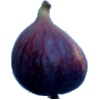

In [10]:
from PIL import Image

image = Image.open("fig_0_100.jpg").convert("RGB")
image

In [11]:
inputs = processor(images=image, return_tensors="pt")
pixel_values = inputs["pixel_values"].to(device)
pixel_values.shape

torch.Size([1, 3, 224, 224])

In [12]:
with torch.inference_mode():
    eager_logits = eager_model(pixel_values)

eager_logits

tensor([[ 3.3162, -4.0915, -3.2217, -2.8835]], device='cuda:0')

In [13]:
probabilities = eager_logits.softmax(dim=-1)
probabilities

tensor([[9.9593e-01, 6.0413e-04, 1.4417e-03, 2.0218e-03]], device='cuda:0')

In [14]:
confidence, class_idx = probabilities[0].max(dim=0)
prediction = labels[class_idx.item()]
prediction, confidence.item()

('Fig', 0.995932400226593)

In [15]:
def rank_predictions(probabilities, labels):
    scores, indices = probabilities.sort(descending=True)
    return [{"label": labels[idx], "score": float(score)}
            for score, idx in zip(scores.tolist(), indices.tolist())]

In [16]:
predictions = rank_predictions(probabilities[0], labels)
predictions

[{'label': 'Fig', 'score': 0.995932400226593},
 {'label': 'Orange', 'score': 0.0020218421705067158},
 {'label': 'Onion White', 'score': 0.0014416880439966917},
 {'label': 'Mandarine', 'score': 0.0006041254382580519}]

In [17]:
def choose_prediction(predictions, threshold=0.5):
    best = predictions[0]

    if (best["score"] >= threshold):
        return best["label"]

    return "Uncertain"

In [18]:
choose_prediction(predictions, threshold=0.5)

'Fig'

## 11.5 Establishing a Performance Baseline

In [19]:
def synchronize():
    if device.type != "cpu":
        torch.accelerator.synchronize(device)

In [20]:
import time

def benchmark_model(model, x, warmup=10, repeats=100):
    model.eval()
    with torch.inference_mode():
        # Warm-up to perform one-off steps
        for _ in range(warmup):
            model(x)
        synchronize()

        times = []
        # Loops over to get measurements
        for _ in range(repeats):
            start = time.perf_counter()
            model(x)
            # Ensures the end time is only assigned
            # after CUDA effectively finishes
            synchronize()
            end = time.perf_counter()
            times.append(end - start)

    # Compute statistics
    times = torch.tensor(times)
    return {"mean_ms": times.mean().item() * 1000,
            "median_ms": times.median().item() * 1000,
            "p95_ms": torch.quantile(times, 0.95).item() * 1000}

In [21]:
eager_metrics = benchmark_model(eager_model, pixel_values)
eager_metrics

{'mean_ms': 3.3538127318024635,
 'median_ms': 2.986733103170991,
 'p95_ms': 3.979072906076908}

## 11.6 Compiling the Model

In [22]:
compiled_model = torch.compile(eager_model)

### 11.6.4 The First Compiled Execution

In [23]:
synchronize()
start = time.perf_counter()

with torch.inference_mode():
    compiled_logits = compiled_model(pixel_values)

synchronize()
first_call = time.perf_counter() - start
print(f"First compiled call: {first_call:.3f} s")

W1106 18:21:29.110000 642 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


First compiled call: 21.025 s


In [24]:
torch.testing.assert_close(compiled_logits, eager_logits, rtol=1e-4, atol=1e-5)

compiled_probs = compiled_logits.softmax(dim=-1)
compiled_idx = compiled_probs[0].argmax().item()
labels[compiled_idx]

'Fig'

### 11.6.5 Benchmarking the Compiled Model

In [25]:
compiled_metrics = benchmark_model(compiled_model, pixel_values)
compiled_metrics

{'mean_ms': 3.8143929559737444,
 'median_ms': 2.8203430119901896,
 'p95_ms': 5.660537630319595}

In [26]:
import pandas as pd

pd.DataFrame({"Eager": eager_metrics, "Compiled": compiled_metrics})

,Eager,Compiled
mean_ms,3.353813,3.814393
median_ms,2.986733,2.820343
p95_ms,3.979073,5.660538


In [27]:
speedup = eager_metrics["median_ms"] / compiled_metrics["median_ms"]
print(f"Median speedup: {speedup:.2f}x")

Median speedup: 1.06x


## 11.7 Exporting the Model

In [28]:
export_checkpoint = torch.load("fomo_model_2026.pth", map_location="cpu", weights_only=True)
export_labels = export_checkpoint["labels"]
export_repo_id = export_checkpoint["repo_id"]

export_id2label = {idx: label for idx, label in enumerate(export_labels)}
export_label2id = {label: idx for idx, label in export_id2label.items()}
export_config = AutoConfig.from_pretrained(
    export_repo_id,
    num_labels=len(export_labels),
    id2label=export_id2label,
    label2id=export_label2id,
)

export_base_model = AutoModelForImageClassification.from_config(export_config)
export_base_model.load_state_dict(export_checkpoint["model_state_dict"])

export_model = LogitsModel(export_base_model)
export_model.eval()

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


LogitsModel(
  (model): ResNetForImageClassification(
    (resnet): ResNetModel(
      (embedder): ResNetEmbeddings(
        (embedder): ResNetConvLayer(
          (convolution): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
          (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (activation): ReLU()
        )
        (pooler): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      )
      (encoder): ResNetEncoder(
        (stages): ModuleList(
          (0): ResNetStage(
            (layers): Sequential(
              (0): ResNetBasicLayer(
                (shortcut): Identity()
                (layer): Sequential(
                  (0): ResNetConvLayer(
                    (convolution): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
                    (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bia

In [29]:
export_input = pixel_values.detach().cpu()

In [30]:
exported_program = torch.export.export(export_model, args=(export_input,))
print(exported_program)

ExportedProgram:
    class GraphModule(torch.nn.Module):
        def forward(self, p_model_resnet_embedder_embedder_convolution_weight: "f32[64, 3, 7, 7]", p_model_resnet_embedder_embedder_normalization_weight: "f32[64]", p_model_resnet_embedder_embedder_normalization_bias: "f32[64]", p_model_resnet_encoder_stages_0_layers_0_layer_0_convolution_weight: "f32[64, 64, 3, 3]", p_model_resnet_encoder_stages_0_layers_0_layer_0_normalization_weight: "f32[64]", p_model_resnet_encoder_stages_0_layers_0_layer_0_normalization_bias: "f32[64]", p_model_resnet_encoder_stages_0_layers_0_layer_1_convolution_weight: "f32[64, 64, 3, 3]", p_model_resnet_encoder_stages_0_layers_0_layer_1_normalization_weight: "f32[64]", p_model_resnet_encoder_stages_0_layers_0_layer_1_normalization_bias: "f32[64]", p_model_resnet_encoder_stages_0_layers_1_layer_0_convolution_weight: "f32[64, 64, 3, 3]", p_model_resnet_encoder_stages_0_layers_1_layer_0_normalization_weight: "f32[64]", p_model_resnet_encoder_stages_0_layers

In [31]:
torch.export.save(exported_program, "fomo.pt2")

## 11.8 FastAPI

So far, all of our predictions have been made from Python code running in the same process as the model. That works well in a notebook, but it is not how a model is usually exposed to another application. A web application, mobile app, or another backend service should not need direct access to our PyTorch objects. Instead, it can send a request over HTTP and receive a response containing the prediction. To build that interface, we'll use **FastAPI**.

FastAPI is a Python framework for building web APIs using ordinary Python functions and type annotations. At its simplest, we create an application object and associate Python functions with HTTP methods and paths:

```python
from fastapi import FastAPI

app = FastAPI()

@app.get("/")
def root():
    return {"message": "Hello"}
```

The decorator `@app.get("/")` means that the function immediately below it should handle an HTTP `GET` request sent to the `/` path. If the function returns a Python dictionary, FastAPI serializes it into a JSON response automatically.

So the sequence of events is roughly: client makes an HTTP request, FastAPI uses path and method to determine which Python function to call, Python function returns a value, FastAPI serializes it into a JSON response.

FastAPI supports the standard HTTP methods we'll typically use when building APIs, including `GET`, `POST`, `PUT`, and `DELETE`. For our model-serving example, the distinction is straightforward: we'll use `GET` for a health-check endpoint that simply reports whether the service is running, and `POST` for predictions because the client needs to send an image to the server.

One particularly useful feature of FastAPI is that Python type annotations are also used to describe and validate the API. For example:

```python
@app.get("/square")
def square(value: float):
    return {"result": value ** 2}
```

FastAPI understands that `value` should be a floating-point number and uses that information both to validate incoming requests and to describe the endpoint. This becomes particularly useful when an API accepts or returns more structured data. FastAPI integrates with Pydantic, allowing us to define explicit schemas for requests and responses using Python classes. Those schemas can then be used for validation as well as documentation.

FastAPI also generates an **OpenAPI schema** automatically. OpenAPI (do not confuse with OpenAI) is a standard description of an API: its available paths, accepted parameters, request bodies, and response structures. FastAPI uses that schema to generate interactive documentation without requiring us to write separate documentation by hand.

Once the application is running, the documentation is normally available at `http://127.0.0.1:8000/docs`, where FastAPI provides an interactive Swagger UI. From there, we can inspect each endpoint, provide values or upload files, send requests, and examine the responses directly from the browser.

FastAPI itself defines the application and its routes, but an ASGI server is responsible for actually listening for HTTP connections and running the application. When FastAPI is installed with its standard dependencies, Uvicorn is included for this purpose. The command below loads the application and serves it over HTTP:

```bash
fastapi run app.py
```

This gives us a useful separation of responsibilities:
- PyTorch: model inference
- FastAPI: API definition, validation, and serialization
- Uvicorn: HTTP server

FastAPI's role is simply to provide a clean interface between our Python inference code and the applications that want to use it.

Now, we're ready to turn the FOMO classifier into an API.

## 11.9 Serving a Model using FastAPI

### 11.9.1 The Runtime Code

In [32]:
%%writefile runtime.py

import torch
from transformers import AutoConfig, AutoImageProcessor, AutoModelForImageClassification
from torch import nn

class LogitsModel(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, pixel_values):
        return self.model(pixel_values=pixel_values).logits

def load_fomo(checkpoint_path, device):
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)

    repo_id = checkpoint["repo_id"]
    labels = checkpoint["labels"]
    id2label = {idx: label for idx, label in enumerate(labels)}
    label2id = {label: idx for idx, label in id2label.items()}

    config = AutoConfig.from_pretrained(
        repo_id,
        num_labels=len(labels),
        id2label=id2label,
        label2id=label2id,
    )

    base_model = AutoModelForImageClassification.from_config(config)
    base_model.load_state_dict(checkpoint["model_state_dict"])
    model = LogitsModel(base_model)
    model.to(device)
    model.eval()

    processor = AutoImageProcessor.from_pretrained(repo_id)

    return (model, processor, labels)

def rank_predictions(probabilities, labels):
    scores, indices = probabilities.sort(descending=True)

    return [{"label": labels[idx], "score": float(score)}
            for score, idx in zip(scores.tolist(), indices.tolist())]

def predict_image(model, processor, labels, image, device, threshold=0.5):
    image = image.convert("RGB")
    inputs = processor(images=image, return_tensors="pt")
    pixel_values = inputs["pixel_values"].to(device)

    with torch.inference_mode():
        logits = model(pixel_values)

    probabilities = logits[0].softmax(dim=-1).cpu()
    predictions = rank_predictions(probabilities, labels)
    best = predictions[0]
    prediction = best["label"] if best["score"] >= threshold else "Uncertain"

    return {"prediction": prediction, "confidence": best["score"], "predictions": predictions}

Writing runtime.py


### 11.9.2 The Application Code

In [33]:
%%writefile app.py

from contextlib import asynccontextmanager
from typing import Annotated
import torch
from fastapi import FastAPI, HTTPException, Query, UploadFile
from PIL import Image, UnidentifiedImageError
from pydantic import BaseModel
from runtime import load_fomo, predict_image

CHECKPOINT_PATH = "fomo_model_2026.pth"

def get_device():
    return (torch.accelerator.current_accelerator(check_available=True) or torch.device("cpu"))

@asynccontextmanager
async def lifespan(app):
    ########################################
    # Runs when application starts         #
    ########################################
    device = get_device()
    model, processor, labels = load_fomo(CHECKPOINT_PATH, device)
    model = torch.compile(model)

    dummy_image = Image.new("RGB", (224, 224))
    dummy_inputs = processor(images=dummy_image, return_tensors="pt")
    dummy_values = dummy_inputs["pixel_values"].to(device)

    with torch.inference_mode():
        model(dummy_values)

    if device.type != "cpu":
        torch.accelerator.synchronize(device)

    app.state.model = model
    app.state.processor = processor
    app.state.labels = labels
    app.state.device = device
    ########################################
    yield  # Application is running
    ########################################
    # Runs when application shuts down     #
    ########################################
    app.state.model = None
    app.state.processor = None
    app.state.labels = None
    ########################################

# Create the app
app = FastAPI(title="FOMO Classification API", version="1.0", lifespan=lifespan)

class ClassScore(BaseModel):
    label: str
    score: float

class PredictionResponse(BaseModel):
    prediction: str
    confidence: float
    predictions: list[ClassScore]

@app.get("/health")
def health():
    return {"status": "ok", "device":str(app.state.device), "compiled": True}

@app.post("/predict", response_model=PredictionResponse)
def predict(file: UploadFile, threshold: Annotated[float, Query(ge=0.0, le=1.0)] = 0.5):
    if file.content_type is None or not file.content_type.startswith("image/"):
        raise HTTPException(status_code=415, detail=("The uploaded file must be an image."))

    try:
        image = Image.open(file.file).convert("RGB")
    except (UnidentifiedImageError, OSError):
        raise HTTPException(status_code=400, detail=("The uploaded file could not be decoded as an image."))

    return predict_image(
        app.state.model,
        app.state.processor,
        app.state.labels,
        image,
        app.state.device,
        threshold=threshold,
    )

Writing app.py


### 11.9.3 Testing the Application with a Client

In [34]:
from fastapi.testclient import TestClient
from app import app

with TestClient(app) as client:
    response = client.get("/health")

response.json()

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


{'status': 'ok', 'device': 'cuda', 'compiled': True}

In [35]:
with TestClient(app) as client:
    with open("fig_0_100.jpg", "rb") as file:
        response = client.post("/predict", params={"threshold": 0.5}, files={"file": ("fig.jpg", file, "image/jpeg")})

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


In [36]:
response.status_code, response.json()

(200,
 {'prediction': 'Fig',
  'confidence': 0.995932400226593,
  'predictions': [{'label': 'Fig', 'score': 0.995932400226593},
   {'label': 'Orange', 'score': 0.0020218375138938427},
   {'label': 'Onion White', 'score': 0.0014416963094845414},
   {'label': 'Mandarine', 'score': 0.0006041288143023849}]})

### 11.9.4 Running the Server

In [37]:
import subprocess
import time
import requests

PORT = 8000
log = open("fastapi.log", "w")
server = subprocess.Popen(["fastapi", "run", "app.py", "--port", str(PORT)], stdout=log, stderr=subprocess.STDOUT)

In [38]:
for _ in range(120):
    try:
        response = requests.get(f"http://127.0.0.1:{PORT}/health", timeout=1)
        if response.ok:
            break
    except requests.ConnectionError:
        pass
    time.sleep(0.5)
else:
    raise RuntimeError("FastAPI did not start.")

response.json()

{'status': 'ok', 'device': 'cuda', 'compiled': True}

In [39]:
from google.colab import output

output.serve_kernel_port_as_iframe(PORT, path="/docs", height=800)

<IPython.core.display.Javascript object>

In [40]:
import requests

url = "http://127.0.0.1:8000/predict"

with open("fig_0_100.jpg", "rb") as file:
    response = requests.post(url, params={"threshold": 0.5}, files={"file": ("fig.jpg", file, "image/jpeg")})

response.raise_for_status()
prediction = response.json()
prediction

{'prediction': 'Fig',
 'confidence': 0.995932400226593,
 'predictions': [{'label': 'Fig', 'score': 0.995932400226593},
  {'label': 'Orange', 'score': 0.0020218375138938427},
  {'label': 'Onion White', 'score': 0.0014416963094845414},
  {'label': 'Mandarine', 'score': 0.0006041288143023849}]}

### 11.9.5 Benchmarking the Application

In [41]:
import time

latencies = []

for _ in range(20):
    with open("fig_0_100.jpg", "rb") as file:
        start = time.perf_counter()
        response = requests.post(url, params={"threshold": 0.5}, files={"file": ("fig.jpg", file, "image/jpeg")})
        response.raise_for_status()
        end = time.perf_counter()

    latencies.append(end - start)

In [42]:
latencies = torch.tensor(latencies)

print("Mean:", latencies.mean().item() * 1000, "ms",)
print("Median:", latencies.median().item() * 1000, "ms")

Mean: 10.259301401674747 ms
Median: 9.986638091504574 ms


### 11.9.6 Shutting Down

In [43]:
server.terminate()
server.wait()
log.close()
print(open("fastapi.log").read())


 ⚡️ Starting FastAPI in production mode
 
 🐍 Using import string: app:app
 
 🌐 Server started at http://0.0.0.0:8000
    Documentation at http://0.0.0.0:8000/docs
 
  Logs:
 
INFO:     Started server process [3719]
INFO:     Waiting for application startup.
[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:43708 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:43724 - "GET /docs HTTP/1.1" 200 OK
INFO:     127.0.0.1:43738 - "GET /openapi.json HTTP/1.1" 200 OK
INFO:     127.0.0.1:46072 - "POST /predict?threshold=0.5 HTTP/1.1" 200 OK
INFO:     127.0.0.1:46076 - "POST /predict?threshold=0.5 HTTP/1.1" 200 OK
INFO:     127.0.0.1:46088 - "POST /predict?threshold=0.5 HTTP/1.1" 200 OK
INFO:     127.0.0.1:46090 - "POST /predict?threshold=0.5 HTTP/1.1" 200 OK
INFO:     127.0.0.1:46094 - "POST /predict?threshold